# 01 · Spend categoriser — the story

**Question:** given one SBI bank-statement line such as

`TO TRANSFER-UPI/DR/512345678902/RAJU TEA/PYTM/paytmqr1y7/UPI-` · ₹25

which kind of spending is it? (tea/snacks, meals, food delivery, groceries, transport, shopping, entertainment, bills, subscriptions, transfers to people, ATM cash, other)

**Why it is hard:** SBI cuts the payee name to ~8 characters, small shops and people have names no dictionary knows, and the same ₹100 could be a meal, an auto ride or a friend.

**Idea:** combine what the line *says* (text) with how the payee *behaves* over the whole statement (₹25, several times a day, every day → tea stall).

This notebook reads the results written by `ml/scripts/train_categoriser.py` (`ml/reports/results.json`) — run that script first. Nothing here re-trains.

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
while not (ROOT / "ml").exists():
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT / "ml"), str(ROOT / "web" / "src" / "python")]
res = json.loads((ROOT / "ml/reports/results.json").read_text())
train = pd.read_csv(ROOT / "ml/data/training_set.csv")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
print(f"model v{res['model_version']} trained {res['trained_at']} · {len(train):,} training rows")

model v1.0 trained 2026-11-23 · 23,692 training rows


## 1. Data: training and test never meet

* **Training:** synthetic statements for 12 made-up users in **2024**, generated from a hand-written list of real Indian merchants (`ml/data/merchant_labels.csv`) plus invented tea stalls, canteens, auto drivers and friends — with their **own name lists and random stream**.
* **Test:** the demo statement (one student, Nov 2025 – Nov 2026) and its answer key. Used **once**, at the very end.

Both are deliberately *unbalanced*, like real spending: lots of tea, few subscriptions.

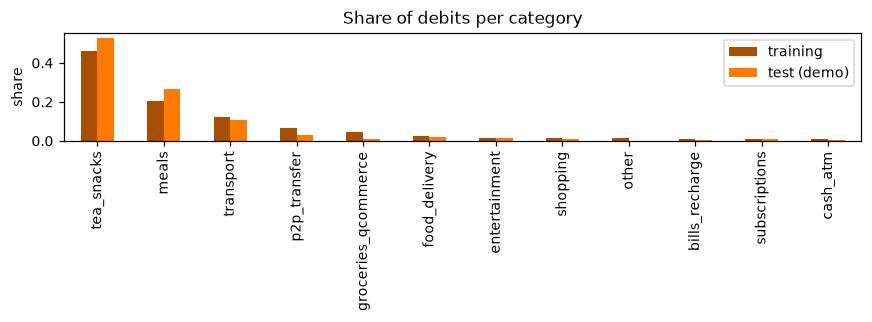

,description,debit,category
0,TO TRANSFER-UPI/DR/875521696119/DURGA FO/UTIB/...,40.0,meals
1,TO TRANSFER-UPI/DR/358055738248/BHARATH /INDB/...,25.0,tea_snacks
2,TO TRANSFER-UPI/DR/310453211891/PRABHU R/YESB/...,70.0,transport
9,TO TRANSFER-UPI/DR/904640784896/CHAI PO/ICIC/c...,228.0,entertainment
18,TO TRANSFER-UPI/DR/841044689369/DMART/HDFC/dma...,2063.0,groceries_qcommerce
24,TO TRANSFER-UPI/DR/770035672772/VIVAAN P/SBIN/...,170.0,p2p_transfer
25,TO TRANSFER-UPI/DR/360144182921/SWIGGY/UTIB/sw...,434.0,food_delivery
47,TO TRANSFER-UPI/DR/639399887127/STATIONE/YESB/...,412.0,shopping
128,TO TRANSFER-UPI/DR/482142636617/APOLLO P/ICIC/...,1194.0,other
166,TO TRANSFER-UPI/DR/523138413417/TATA POW/ICIC/...,2499.0,bills_recharge


In [2]:
share = pd.DataFrame({"training": res["data"]["train_class_share"], "test (demo)": res["data"]["test_class_share"]}).fillna(0)
share = share.sort_values("training", ascending=False)
share.plot.bar(figsize=(8, 3), color=["#a84e00", "#ff7a00"], title="Share of debits per category")
plt.ylabel("share"); plt.tight_layout(); plt.show()
train.groupby("category").head(1)[["description", "debit", "category"]]

## 2. What the model sees

Each line is parsed with the **same SBI parser the app uses**, then turned into features (`ml/selfscope_ml/features.py`, shared byte-for-byte with the browser):

| group | example |
|---|---|
| text | character 2–5-grams of `raju tea paytmqr000 upi` + `bank:pytm` |
| rule flags | channel = UPI, shop QR handle = yes, person-like UPI ID = no, keyword says *tea_snacks* |
| amount | log(25), bucket ≤ ₹30 |
| payee behaviour | 400 payments, 1.1 per active day, median ₹25, paid on 85% of days |

In [3]:
from selfscope_ml import features as F
row = {"counterparty": "RAJU TEA", "vpa_fragment": "paytmqr1y7", "note": "UPI", "bank_code": "PYTM", "channel": "UPI",
       "amount": 25.0, "is_debit": True, "local_date": "2026-03-02", "weekday": 0}
stats = {F.payee_key(row): {"count": 400, "active_days": 310, "per_active_day": 1.29, "median": 25.0, "std": 2.0,
                            "weekend_share": 0.28, "density": 0.85}}
print(F.analyzer(F.text_doc(row))[:14], "…")
pd.Series(F.dense_features(row, stats), index=F.DENSE_NAMES).round(3).to_frame("value").T

[' r', 'ra', 'aj', 'ju', 'u ', ' ra', 'raj', 'aju', 'ju ', ' raj', 'raju', 'aju ', ' raju', 'raju '] …


,ch_upi,ch_neft,ch_imps,ch_atm,ch_mandate,ch_other,person_vpa,phone_vpa,merchant_qr,user_note,...,amt_gt_5000,payee_log_count,payee_per_active_day,payee_log_median,payee_log_std,payee_cv,payee_weekend_share,payee_density,payee_log_active_days,amount_vs_payee_median
value,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,5.994,1.29,3.258,1.099,0.08,0.28,0.85,5.74,0.0


## 3. Three approaches compared

Cross-validation uses **GroupKFold by payee**: every payee is either in training or in validation, never both — so the score says how well a model copes with payees it has *never seen*.

,cv_acc,cv_macro_f1,cv_macro_f1_std,test_acc,test_macro_f1,config
a) rules only,0.5189,0.551,0.036,0.7287,0.8411,rules
b) text only,0.6418,0.5622,0.0445,0.8016,0.8143,text C=8.0 cw=balanced
c) full model,0.9055,0.8036,0.0279,0.9618,0.9652,full C=0.5 cw=balanced


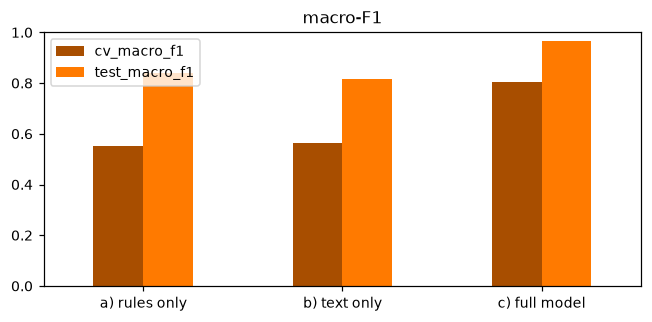

,cv_macro_f1,cv_acc
full C=0.5 cw=balanced,0.8036,0.9055
full C=2.0 cw=balanced,0.8022,0.9072
full C=8.0 cw=balanced,0.8003,0.8998
full C=2.0 cw=None,0.7997,0.9075
full C=0.5 cw=None,0.7990,0.9074
full C=8.0 cw=None,0.7936,0.8986


In [4]:
cmp = pd.DataFrame(res["comparison"]).T[["cv_acc", "cv_macro_f1", "cv_macro_f1_std", "test_acc", "test_macro_f1", "config"]]
cmp.index = ["a) rules only", "b) text only", "c) full model"]
display(cmp)
ax = cmp[["cv_macro_f1", "test_macro_f1"]].plot.bar(figsize=(6, 3), color=["#a84e00", "#ff7a00"], rot=0, ylim=(0, 1), title="macro-F1")
plt.tight_layout(); plt.show()
pd.DataFrame(res["grid"]).T.sort_values("cv_macro_f1", ascending=False).head(6)

**Reading it:** text alone is weak on unseen payees (a new canteen's name tells it little). Adding the rule flags, amount and especially **payee behaviour** is what makes the difference. The test score is higher than cross-validation because the demo statement is a tidy routine with many well-known brands; the cross-validation number is the cautious estimate.

## 4. Final test on the demo statement

In [5]:
t = res["test"]
print(f"accuracy {t['accuracy']:.1%} · macro-F1 {t['macro_f1']:.3f} on {t['debits']:,} debits")
print(f"known brands/keywords: {res['test_known_vs_unknown']['known_acc']:.1%} · unknown local payees & people: {res['test_known_vs_unknown']['unknown_acc']:.1%}")
pd.DataFrame(res["per_class"]).T.round(2)

accuracy 96.2% · macro-F1 0.965 on 2,565 debits
known brands/keywords: 100.0% · unknown local payees & people: 94.7%


,precision,recall,f1-score,support
bills_recharge,1.00,1.00,1.00,12.0
cash_atm,1.00,1.00,1.00,10.0
entertainment,1.00,1.00,1.00,39.0
food_delivery,1.00,1.00,1.00,49.0
groceries_qcommerce,0.85,1.00,0.92,29.0
meals,1.00,0.87,0.93,682.0
p2p_transfer,1.00,0.83,0.91,72.0
shopping,1.00,1.00,1.00,21.0
subscriptions,1.00,1.00,1.00,24.0
tea_snacks,1.00,1.00,1.00,1355.0


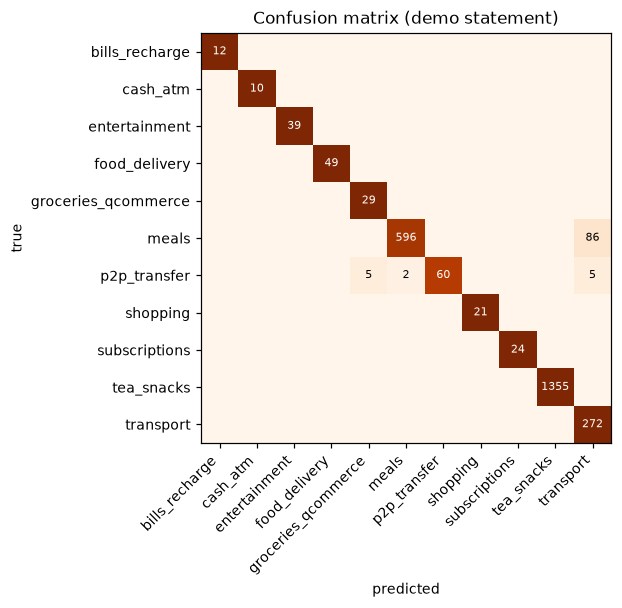

,true,pred,count
0,meals,transport,86
1,p2p_transfer,groceries_qcommerce,5
2,p2p_transfer,transport,5
3,p2p_transfer,meals,2


In [6]:
import numpy as np
labels, cm = res["confusion"]["labels"], np.array(res["confusion"]["matrix"])
cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(7, 5.6))
ax.imshow(cmn, cmap="Oranges", vmin=0, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right"); ax.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cmn[i, j] > .6 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Confusion matrix (demo statement)")
plt.tight_layout(); plt.show()
pd.DataFrame(res["top_confusions"]).head(5)

## 5. How sure is the model? The REVIEW threshold

If the model's top probability is below the threshold, the app shows the payment as **other** and lists it under **REVIEW** for the user. The threshold is chosen on out-of-fold training predictions (not on the test set) as the smallest value where the kept predictions are ≥ 95% accurate.

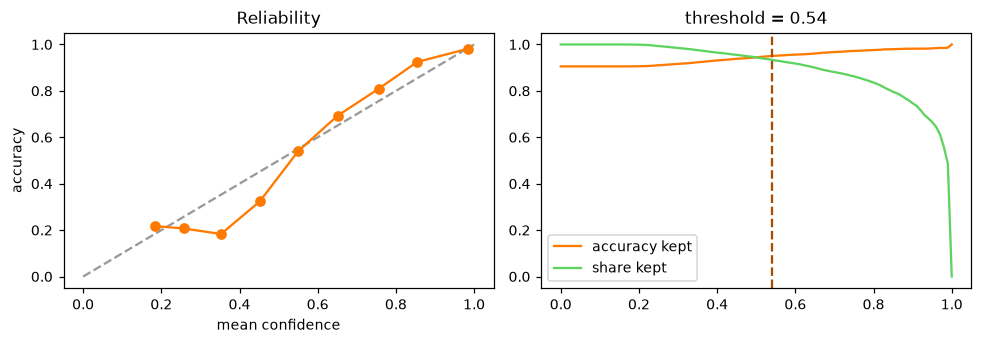

demo statement: 57 of 2,565 debits (2.2%) go to REVIEW: {'p2p_transfer': 19, 'meals': 38}


In [7]:
th = res["threshold"]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
rel = pd.DataFrame(th["reliability"])
axes[0].plot([0, 1], [0, 1], "--", color="#9a9a9a"); axes[0].plot(rel.conf, rel.acc, "o-", color="#ff7a00")
axes[0].set(xlabel="mean confidence", ylabel="accuracy", title="Reliability")
cur = pd.DataFrame(th["curve"])
axes[1].plot(cur.t, cur.acc, color="#ff7a00", label="accuracy kept"); axes[1].plot(cur.t, cur.coverage, color="#5fd35f", label="share kept")
axes[1].axvline(th["value"], color="#a84e00", ls="--"); axes[1].legend(); axes[1].set(title=f"threshold = {th['value']:.2f}")
plt.tight_layout(); plt.show()
print(f"demo statement: {t['review_count']} of {t['debits']:,} debits ({t['review_share']:.1%}) go to REVIEW:", res["review_by_true_class"])

## 6. Where it goes wrong

Errors cluster by **payee**: the model treats all payments to one payee alike, so one confusing payee produces many errors.

In [8]:
display(pd.DataFrame(res["errors_by_payee"]))
pd.DataFrame(res["mistakes"])[["payee", "upi_id", "amount", "true", "pred", "confidence", "reason"]]

,payee,errors
0,annapoor|annapoorna,71
1,dakshin|dakshinmes,13
2,rohan ku|rohank98@o,4
3,varun ra|varunrao@o,3
4,karthik|karthik.s@,3
5,udupi gr|udupigrand,2
6,priya sh|priyasharm,1
7,ishita r|ishita.r@o,1


,payee,upi_id,amount,true,pred,confidence,reason
0,VARUN RA,varunrao@o,60.0,p2p_transfer,transport,0.818,"a friend paid repeatedly (31 payments, median ..."
1,ANNAPOOR,annapoorna,100.0,meals,transport,0.813,UPI ID 'annapoorna' has no shop word (SBI keep...
2,UDUPI GR,udupigrand,100.0,meals,transport,0.659,UPI ID 'udupigrand' has no shop word (SBI keep...
3,DAKSHIN,dakshinmes,100.0,meals,transport,0.538,UPI ID 'dakshinmes' has no shop word (SBI keep...
4,PRIYA SH,priyasharm,480.0,p2p_transfer,groceries_qcommerce,0.518,"a friend paid repeatedly (14 payments, median ..."
5,ISHITA R,ishita.r@o,210.0,p2p_transfer,meals,0.436,"a friend paid repeatedly (2 payments, median ₹..."
6,ROHAN KU,rohank98@o,80.0,p2p_transfer,transport,0.377,"a friend paid repeatedly (13 payments, median ..."
7,ROHAN KU,rohank98@o,370.0,p2p_transfer,groceries_qcommerce,0.355,"a friend paid repeatedly (13 payments, median ..."
8,KARTHIK,karthik.s@,410.0,p2p_transfer,groceries_qcommerce,0.203,"a friend paid repeatedly (11 payments, median ..."
9,KARTHIK,karthik.s@,430.0,p2p_transfer,transport,0.203,"a friend paid repeatedly (11 payments, median ..."


The biggest one is a canteen whose UPI ID `annapoornamess@…` is printed by SBI as `annapoorna` — without *mess* it looks like a person's name, and in training, name-like IDs with small fixed daily amounts were mostly **auto drivers**.

We did **not** patch the training data after seeing this, because that would tune the model on the test set. Instead:

* in the app, one correction with *"apply to all payments to this payee"* fixes every row of that payee (user corrections always win and survive re-imports);
* the next model version should add shops whose shop word is cut off, and be checked on a **new** unseen statement.

## 7. Limitations

* Synthetic data on both sides — real-world accuracy is unknown and probably lower.
* Truncated names collide; brands never seen are only recognised by behaviour.
* Labelling conventions (cafe = entertainment, canteen = meals, friend paying back = income) decide some "errors".
* Behaviour needs history: a payee seen once has no routine.

**Retrain:** `python ml/scripts/make_training_set.py && python ml/scripts/train_categoriser.py` — see `ml/reports/categoriser_report.md`.